[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/juansensio/blog/blob/master/096_ml_unsupervised/096_ml_unsupervised.ipynb)

# ML - Aprendizaje No Supervisado

> **Versión modificada:** incorpora los ejercicios solicitados de generación aleatoria y K-Means en 2D y 3D, incluyendo número aleatorio de centroides (1–20), separación visual, dispersión y cantidad de puntos aleatorias, conteo por cluster, cinco puntos más cercanos y gráficas del proceso de entrenamiento.

Si bien todos los ejemplos de *Machine Learning* que hemos visto hasta ahora en esta serie se han basado en aprendizaje supervisado (nuestros datos van acompañados de las etiquetas correspondientes, ejemplos de la tarea que queremos llevar a cabo) la mayoría de los datos no están etiquetados. Antes esta problemática tenemos dos alternativas: etiquetar datos manualmente (lo cual require de tiempo, esfuerzo y dinero en el caso de querer desarrollar sistemas reales) o bien usar técnicas de aprendizaje no supervisado, o *Unsupervised Learning* en inglés.

## Clustering

De entre las diferentes técnicas de aprendizaje no supervisado, el *Clustering* es una de las más usadas. Este técnica consiste en identificar aquellas muestras similares del conjunto de datos y asignarlas a un *cluster*, o grupo. Esto permite aplicaciones tales como: segmentación de clientes, análisis de datos, reducción de la dimensionalidad, detección de anomalías, aprendizaje semi-supervisado, motores de búsqueda e incluso la semgentación de imágenes.

### K-Means

El algoritmo de *K-Means* es uno de los más usados a la hora de aplicar *Clustering*, ya que es un método rápido y eficiente. Vamos a generar un conjunto de datos sintético para aprender a usar esta técnica.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist

# ============================================================
# PUNTO 1 - GENERACIÓN ALEATORIA DE CLUSTERS EN 2D
# ============================================================
# SEMILLA = None  -> cada ejecución genera un dataset diferente.
# Para repetir exactamente un experimento, use por ejemplo SEMILLA = 42.
SEMILLA = None
rng = np.random.default_rng(SEMILLA)

# Cantidad aleatoria de centroides entre 1 y 20
n_centers = int(rng.integers(1, 21))

# Parámetros de separación. La separación mínima es suficientemente grande
# respecto a la dispersión máxima para facilitar la verificación visual.
LIMITE = 50.0
DISTANCIA_MINIMA = 8.0
STD_MIN, STD_MAX = 0.55, 1.80
PUNTOS_MIN, PUNTOS_MAX = 70, 220


def generar_centroides_separados(n_centers, dimensiones, limite, distancia_minima, rng):
    """Genera centroides aleatorios manteniendo una distancia mínima entre ellos."""
    centros = []
    intentos = 0
    max_intentos = 100000

    while len(centros) < n_centers and intentos < max_intentos:
        candidato = rng.uniform(-limite, limite, size=dimensiones)
        if not centros or all(np.linalg.norm(candidato - c) >= distancia_minima for c in centros):
            centros.append(candidato)
        intentos += 1

    if len(centros) != n_centers:
        raise RuntimeError("No fue posible ubicar todos los centroides con la separación solicitada.")
    return np.asarray(centros)


# 1) Posiciones aleatorias de los centroides
blob_centers = generar_centroides_separados(
    n_centers=n_centers,
    dimensiones=2,
    limite=LIMITE,
    distancia_minima=DISTANCIA_MINIMA,
    rng=rng
)

# 2) Distancia/dispersión aleatoria de los puntos respecto a cada centroide
blob_std = rng.uniform(STD_MIN, STD_MAX, size=n_centers)

# 3) Número aleatorio de puntos por centroide
puntos_por_centroide_generado = rng.integers(PUNTOS_MIN, PUNTOS_MAX + 1, size=n_centers)

# Generación manual para que cada cluster tenga su propio número de puntos
X_partes = []
y_partes = []
for i, (centro, sigma, n_puntos) in enumerate(
    zip(blob_centers, blob_std, puntos_por_centroide_generado)
):
    puntos = rng.normal(loc=centro, scale=sigma, size=(int(n_puntos), 2))
    X_partes.append(puntos)
    y_partes.append(np.full(int(n_puntos), i, dtype=int))

X = np.vstack(X_partes)
y = np.concatenate(y_partes)

# Mezclar las muestras para evitar que queden ordenadas por cluster
orden = rng.permutation(len(X))
X, y = X[orden], y[orden]

print(f"Número de centroides generados: {n_centers}")
print(f"Número total de puntos: {len(X)}")
print("\nCentroides generadores (2D):")
print(np.round(blob_centers, 3))
print("\nDispersión (sigma) por centroide:")
print(np.round(blob_std, 3))
print("\nNúmero de puntos generados por centroide:")
print(puntos_por_centroide_generado)


Número de centroides generados: 7
Número total de puntos: 982

Centroides generadores (2D):
[[-25.37   43.133]
 [  5.047  17.213]
 [-41.701  -4.613]
 [-21.223  28.698]
 [-43.474  49.79 ]
 [-27.718 -17.406]
 [  5.241   5.32 ]]

Dispersión (sigma) por centroide:
[1.576 0.752 0.997 1.306 1.091 1.378 0.88 ]

Número de puntos generados por centroide:
[128  71  74 130 216 206 157]


In [2]:
import matplotlib.pyplot as plt

def plot_clusters(X, y=None):
    plt.scatter(X[:, 0], X[:, 1], c=y, s=1)
    plt.xlabel("$x_1$", fontsize=14)
    plt.ylabel("$x_2$", fontsize=14, rotation=0)

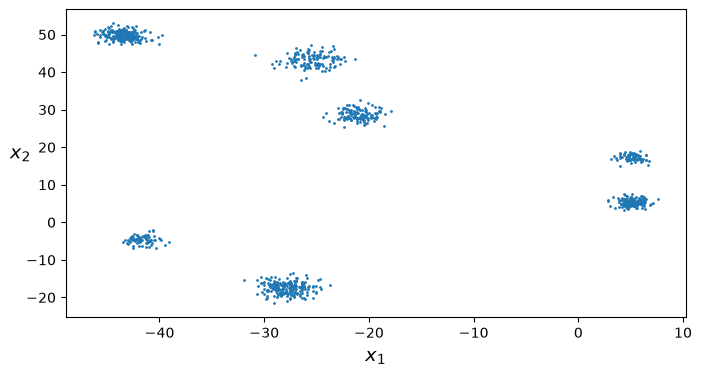

In [3]:
plt.figure(figsize=(8, 4))
plot_clusters(X)
plt.show()

En *Scikit-Learn* puedes usar el objeto [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html), indicando el número de clusters deseado.  

In [4]:
from sklearn.cluster import KMeans
k = len(blob_centers)
#k = 5
kmeans = KMeans(n_clusters=k, random_state=42)
y_pred = kmeans.fit_predict(X)
y_pred         #devolver las etiques de cada grupo y

array([0, 6, 1, 1, 6, 1, 5, 4, 0, 0, 6, 1, 1, 2, 4, 4, 2, 5, 0, 1, 0, 0,
       5, 0, 0, 3, 6, 3, 4, 3, 2, 1, 1, 3, 3, 3, 1, 6, 2, 6, 6, 6, 5, 1,
       1, 3, 2, 2, 0, 1, 0, 1, 5, 6, 1, 2, 3, 1, 6, 2, 0, 0, 0, 6, 2, 0,
       1, 2, 0, 3, 2, 3, 6, 6, 1, 0, 6, 0, 1, 5, 3, 1, 5, 2, 1, 2, 3, 3,
       2, 1, 6, 0, 1, 3, 0, 1, 3, 5, 5, 2, 6, 0, 2, 0, 6, 2, 1, 4, 1, 6,
       0, 1, 0, 3, 2, 4, 0, 3, 1, 5, 3, 3, 3, 6, 6, 6, 0, 5, 2, 1, 1, 4,
       3, 3, 5, 5, 5, 1, 6, 2, 5, 2, 0, 1, 3, 0, 2, 5, 1, 0, 5, 6, 0, 3,
       6, 2, 3, 0, 6, 2, 5, 1, 2, 0, 0, 0, 6, 0, 5, 5, 1, 3, 5, 4, 3, 6,
       1, 4, 1, 3, 3, 1, 3, 0, 1, 2, 3, 1, 0, 3, 2, 3, 1, 0, 1, 1, 5, 1,
       0, 6, 1, 3, 0, 0, 2, 2, 1, 2, 3, 6, 2, 1, 6, 1, 6, 1, 0, 4, 0, 2,
       6, 0, 1, 6, 0, 1, 1, 0, 0, 3, 0, 5, 1, 5, 0, 1, 3, 1, 2, 5, 0, 0,
       6, 1, 6, 1, 0, 6, 5, 1, 6, 5, 3, 2, 4, 0, 5, 6, 4, 0, 3, 4, 2, 4,
       2, 6, 0, 3, 2, 0, 3, 0, 2, 6, 4, 1, 3, 2, 2, 1, 0, 3, 0, 1, 2, 0,
       4, 1, 2, 0, 6, 1, 0, 1, 1, 5, 0, 6, 3, 2, 5,

In [5]:
kmeans.cluster_centers_  # centro de los clusters

array([[-43.45790086,  49.81615015],
       [-27.79852513, -17.38915577],
       [-25.42039273,  43.30200907],
       [  5.13744926,   5.32426948],
       [  5.16612575,  17.23651474],
       [-41.62719141,  -4.61630217],
       [-21.08308854,  28.68917295]])

In [6]:
X_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])  #Predecir nuevas ubicaciones
kmeans.predict(X_new)

array([3, 3, 3, 3], dtype=int32)

In [7]:
def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_centroids(centroids, weights=None, circle_color='w', cross_color='k'):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=10, linewidths=8,
                color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=2, linewidths=10,
                color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=1000, show_centroids=True,
                             show_xlabels=True, show_ylabels=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                cmap="Pastel2")
    plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                linewidths=1, colors='k')
    plot_data(X)
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)

    if show_xlabels:
        plt.xlabel("$x_1$", fontsize=14)
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", fontsize=14, rotation=0)
    else:
        plt.tick_params(labelleft=False)

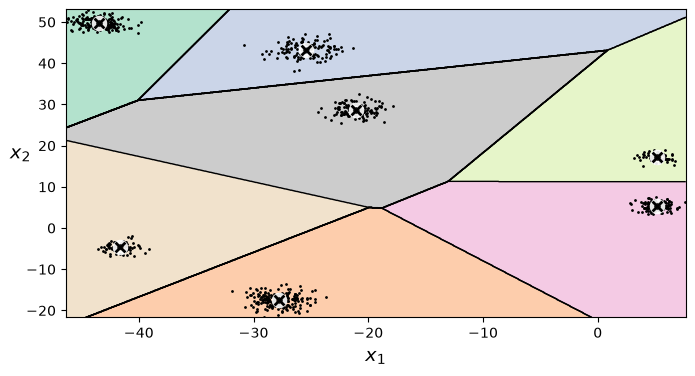

In [8]:
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans, X)
plt.show()

## Actividad solicitada — Punto 1: K-Means con datos 2D

En esta sección se completa el ejercicio solicitado: se aplica **K-Means** al dataset aleatorio generado anteriormente, se informa el número de puntos asignados a cada centroide, se localizan los **5 puntos más cercanos** a cada centroide y se visualiza tanto el resultado final como la evolución del entrenamiento.

In [9]:
# ============================================================
# PUNTO 1 - ENTRENAMIENTO FINAL DE K-MEANS EN 2D
# ============================================================

k = n_centers
kmeans = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
y_pred = kmeans.fit_predict(X)
centroides_finales = kmeans.cluster_centers_

# Cantidad de puntos asignados a cada cluster aprendido
conteos_cluster = np.bincount(y_pred, minlength=k)

print("Resultado final de K-Means (2D)")
print("=" * 45)
print(f"Número de clusters: {k}")
print(f"Inercia final: {kmeans.inertia_:.4f}")
print(f"Iteraciones realizadas: {kmeans.n_iter_}")
print("\nPuntos asignados a cada centroide aprendido:")
for i, cantidad in enumerate(conteos_cluster):
    print(f"  Cluster {i:2d}: {cantidad:4d} puntos | centroide = {np.round(centroides_finales[i], 3)}")


Resultado final de K-Means (2D)
Número de clusters: 7
Inercia final: 2917.7649
Iteraciones realizadas: 2

Puntos asignados a cada centroide aprendido:
  Cluster  0:  216 puntos | centroide = [-43.458  49.816]
  Cluster  1:  206 puntos | centroide = [-27.799 -17.389]
  Cluster  2:  128 puntos | centroide = [-25.42   43.302]
  Cluster  3:  157 puntos | centroide = [5.137 5.324]
  Cluster  4:   71 puntos | centroide = [ 5.166 17.237]
  Cluster  5:   74 puntos | centroide = [-41.627  -4.616]
  Cluster  6:  130 puntos | centroide = [-21.083  28.689]


In [10]:
# ============================================================
# 5 PUNTOS MÁS CERCANOS A CADA CENTROIDE APRENDIDO
# ============================================================

distancias = cdist(X, centroides_finales)
indices_5_cercanos = {}

for i in range(k):
    indices_cluster = np.where(y_pred == i)[0]
    dist_cluster = distancias[indices_cluster, i]
    orden_local = np.argsort(dist_cluster)[:min(5, len(indices_cluster))]
    indices_5_cercanos[i] = indices_cluster[orden_local]

    print(f"\nCluster {i} - 5 puntos más cercanos al centroide {np.round(centroides_finales[i], 3)}")
    for puesto, idx in enumerate(indices_5_cercanos[i], start=1):
        print(
            f"  {puesto}. índice={idx:4d} | punto={np.round(X[idx], 3)} "
            f"| distancia={distancias[idx, i]:.5f}"
        )



Cluster 0 - 5 puntos más cercanos al centroide [-43.458  49.816]
  1. índice= 266 | punto=[-43.445  49.777] | distancia=0.04150
  2. índice= 202 | punto=[-43.63   49.706] | distancia=0.20372
  3. índice= 644 | punto=[-43.67   49.842] | distancia=0.21332
  4. índice= 349 | punto=[-43.656  49.926] | distancia=0.22643
  5. índice= 285 | punto=[-43.643  49.637] | distancia=0.25743

Cluster 1 - 5 puntos más cercanos al centroide [-27.799 -17.389]
  1. índice= 200 | punto=[-27.592 -17.58 ] | distancia=0.28104
  2. índice= 319 | punto=[-27.515 -17.246] | distancia=0.31813
  3. índice= 968 | punto=[-28.126 -17.335] | distancia=0.33163
  4. índice= 691 | punto=[-27.964 -17.737] | distancia=0.38490
  5. índice= 953 | punto=[-28.175 -17.553] | distancia=0.41029

Cluster 2 - 5 puntos más cercanos al centroide [-25.42   43.302]
  1. índice= 574 | punto=[-25.266  43.44 ] | distancia=0.20652
  2. índice= 806 | punto=[-25.581  43.545] | distancia=0.29076
  3. índice= 788 | punto=[-25.732  43.114] | d

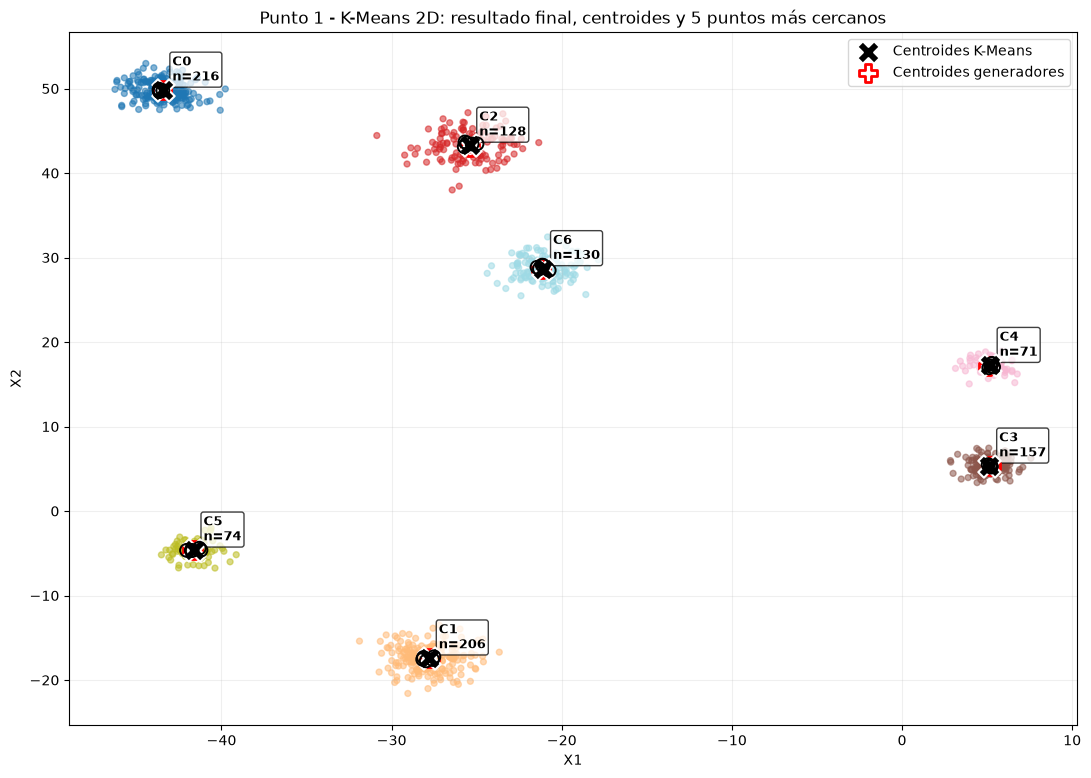

In [11]:
# ============================================================
# GRÁFICA FINAL 2D
# - puntos coloreados por cluster
# - centroides finales
# - cantidad de puntos por cluster
# - 5 puntos más cercanos resaltados
# ============================================================

plt.figure(figsize=(13, 9))
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap="tab20", s=18, alpha=0.55)

# Centroides aprendidos
plt.scatter(
    centroides_finales[:, 0], centroides_finales[:, 1],
    marker="X", s=260, c="black", edgecolors="white", linewidths=1.5,
    label="Centroides K-Means", zorder=6
)

# Centroides originales, útiles para verificación visual
plt.scatter(
    blob_centers[:, 0], blob_centers[:, 1],
    marker="P", s=170, facecolors="none", edgecolors="red", linewidths=2,
    label="Centroides generadores", zorder=5
)

# Cinco puntos más cercanos de cada cluster
for i, indices in indices_5_cercanos.items():
    pts = X[indices]
    plt.scatter(
        pts[:, 0], pts[:, 1],
        s=85, facecolors="none", edgecolors="black", linewidths=1.4, zorder=7
    )
    # Mostrar cantidad de puntos junto al centroide
    cx, cy = centroides_finales[i]
    plt.annotate(
        f"C{i}\nn={conteos_cluster[i]}",
        (cx, cy), xytext=(7, 7), textcoords="offset points",
        fontsize=9, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.75)
    )

plt.title("Punto 1 - K-Means 2D: resultado final, centroides y 5 puntos más cercanos")
plt.xlabel("X1")
plt.ylabel("X2")
plt.grid(alpha=0.2)
plt.legend(loc="best")
plt.show()


### Visualización del proceso de entrenamiento en 2D

Para observar el proceso, se utiliza la misma inicialización aleatoria en todas las ejecuciones parciales y se incrementa `max_iter`. De esta forma se puede comparar la posición de los centroides tras 1, 2, 3, 5 iteraciones y con el modelo convergido.

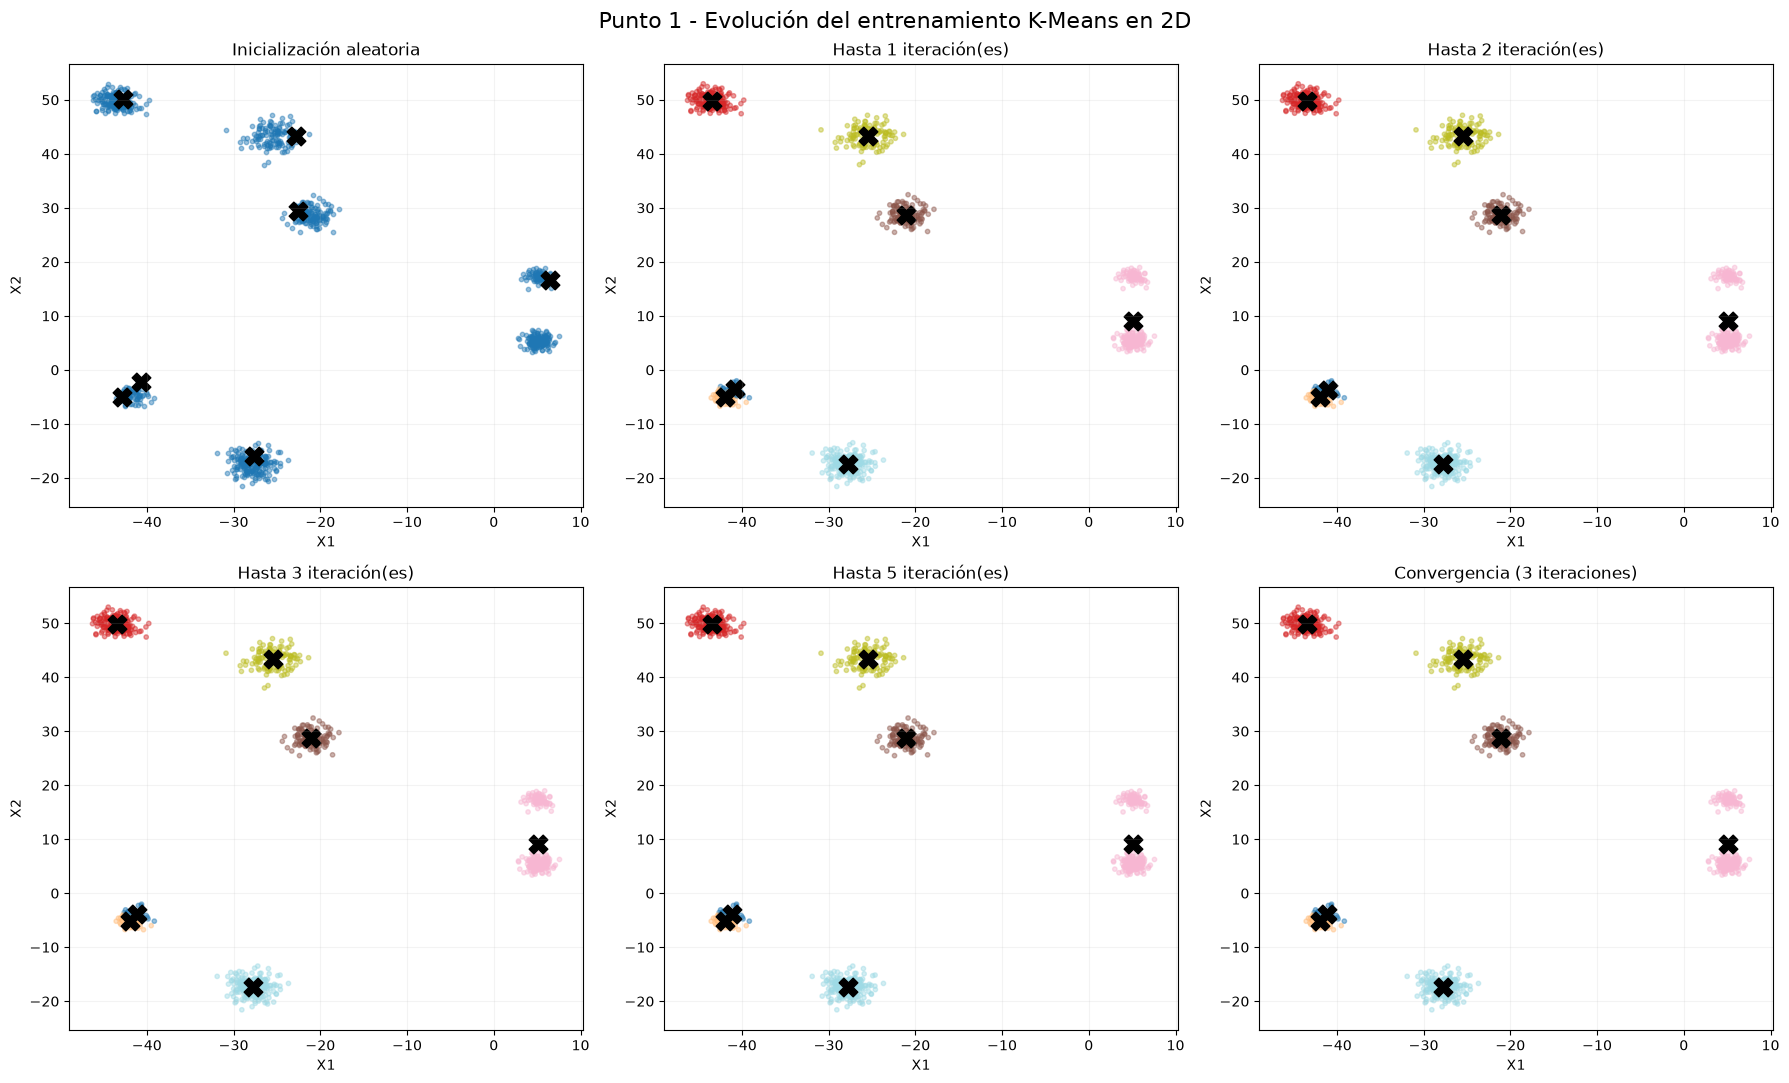

In [12]:
# ============================================================
# PROCESO DE K-MEANS EN 2D
# ============================================================

# Inicialización común para poder comparar iteraciones sucesivas
rng_proceso = np.random.default_rng(123)
indices_init = rng_proceso.choice(len(X), size=k, replace=False)
centros_iniciales = X[indices_init].copy()

iteraciones_mostradas = [1, 2, 3, 5]
modelos_proceso = []

for max_iter in iteraciones_mostradas:
    modelo = KMeans(
        n_clusters=k,
        init=centros_iniciales,
        n_init=1,
        max_iter=max_iter,
        algorithm="lloyd",
        random_state=123
    )
    modelo.fit(X)
    modelos_proceso.append((max_iter, modelo))

modelo_convergido = KMeans(
    n_clusters=k,
    init=centros_iniciales,
    n_init=1,
    max_iter=300,
    algorithm="lloyd",
    random_state=123
).fit(X)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.ravel()

# Panel 0: dataset + centroides iniciales
axes[0].scatter(X[:, 0], X[:, 1], s=10, alpha=0.45)
axes[0].scatter(centros_iniciales[:, 0], centros_iniciales[:, 1], marker="X", s=180, c="black")
axes[0].set_title("Inicialización aleatoria")

# Paneles 1-4: iteraciones parciales
for ax, (max_iter, modelo) in zip(axes[1:5], modelos_proceso):
    etiquetas = modelo.labels_
    ax.scatter(X[:, 0], X[:, 1], c=etiquetas, cmap="tab20", s=10, alpha=0.45)
    ax.scatter(
        modelo.cluster_centers_[:, 0], modelo.cluster_centers_[:, 1],
        marker="X", s=180, c="black"
    )
    ax.set_title(f"Hasta {max_iter} iteración(es)")

# Panel 5: convergencia
axes[5].scatter(X[:, 0], X[:, 1], c=modelo_convergido.labels_, cmap="tab20", s=10, alpha=0.45)
axes[5].scatter(
    modelo_convergido.cluster_centers_[:, 0], modelo_convergido.cluster_centers_[:, 1],
    marker="X", s=180, c="black"
)
axes[5].set_title(f"Convergencia ({modelo_convergido.n_iter_} iteraciones)")

for ax in axes:
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.grid(alpha=0.15)

plt.suptitle("Punto 1 - Evolución del entrenamiento K-Means en 2D", fontsize=16)
plt.tight_layout()
plt.show()


## Actividad solicitada — Punto 2: K-Means con datos 3D

Se repite el procedimiento anterior en tres dimensiones: número aleatorio de centroides, posiciones aleatorias, dispersión aleatoria, cantidad aleatoria de puntos por centroide, entrenamiento con K-Means, conteo de puntos, identificación de los cinco puntos más cercanos y visualización de la evolución del entrenamiento.

In [13]:
# ============================================================
# PUNTO 2 - GENERACIÓN ALEATORIA DE CLUSTERS EN 3D
# ============================================================

SEMILLA_3D = None
rng3 = np.random.default_rng(SEMILLA_3D)

n_centers_3d = int(rng3.integers(1, 21))
LIMITE_3D = 50.0
DISTANCIA_MINIMA_3D = 10.0
STD_MIN_3D, STD_MAX_3D = 0.60, 2.00
PUNTOS_MIN_3D, PUNTOS_MAX_3D = 70, 220

centros_3d_generados = generar_centroides_separados(
    n_centers=n_centers_3d,
    dimensiones=3,
    limite=LIMITE_3D,
    distancia_minima=DISTANCIA_MINIMA_3D,
    rng=rng3
)

std_3d = rng3.uniform(STD_MIN_3D, STD_MAX_3D, size=n_centers_3d)
puntos_por_centroide_3d = rng3.integers(
    PUNTOS_MIN_3D, PUNTOS_MAX_3D + 1, size=n_centers_3d
)

X3_partes = []
y3_partes = []
for i, (centro, sigma, n_puntos) in enumerate(
    zip(centros_3d_generados, std_3d, puntos_por_centroide_3d)
):
    puntos = rng3.normal(loc=centro, scale=sigma, size=(int(n_puntos), 3))
    X3_partes.append(puntos)
    y3_partes.append(np.full(int(n_puntos), i, dtype=int))

X3 = np.vstack(X3_partes)
y3 = np.concatenate(y3_partes)
orden3 = rng3.permutation(len(X3))
X3, y3 = X3[orden3], y3[orden3]

print(f"Número de centroides generados en 3D: {n_centers_3d}")
print(f"Número total de puntos 3D: {len(X3)}")
print("\nCentroides generadores 3D:")
print(np.round(centros_3d_generados, 3))
print("\nDispersión por centroide 3D:")
print(np.round(std_3d, 3))
print("\nNúmero de puntos por centroide 3D:")
print(puntos_por_centroide_3d)


Número de centroides generados en 3D: 18
Número total de puntos 3D: 2356

Centroides generadores 3D:
[[ 23.671   4.794 -26.874]
 [ 19.468  16.317 -16.119]
 [ 24.314  25.896 -45.116]
 [ 13.774   1.298  18.297]
 [-27.172 -27.925  -8.535]
 [-22.624 -11.005 -35.27 ]
 [ 40.27   26.618 -20.641]
 [ -4.093 -39.369  39.15 ]
 [  5.998  -4.807  30.878]
 [-16.3    14.701 -21.916]
 [ 47.432  -3.946 -24.394]
 [ 14.101  19.293 -41.522]
 [ 34.523 -24.598 -14.233]
 [-41.591  39.026 -35.014]
 [-34.973  40.588  35.102]
 [-29.17  -22.546  18.032]
 [  4.84   39.056 -35.922]
 [ 48.02   40.74  -37.59 ]]

Dispersión por centroide 3D:
[1.945 1.519 0.867 1.129 0.709 1.964 0.691 1.945 1.235 1.198 1.856 1.589
 1.471 0.698 1.661 1.582 1.654 1.19 ]

Número de puntos por centroide 3D:
[125 210 202 141 106 163  81 112 143 159  80  74 114 114 150  92 154 136]


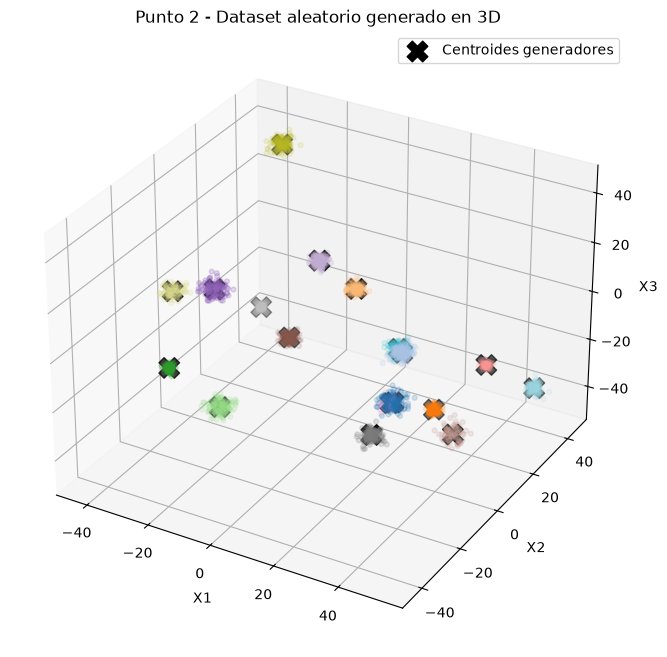

In [14]:
# Dataset generado en 3D
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X3[:, 0], X3[:, 1], X3[:, 2], c=y3, cmap="tab20", s=12, alpha=0.5)
ax.scatter(
    centros_3d_generados[:, 0], centros_3d_generados[:, 1], centros_3d_generados[:, 2],
    marker="X", s=220, c="black", label="Centroides generadores"
)
ax.set_title("Punto 2 - Dataset aleatorio generado en 3D")
ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_zlabel("X3")
ax.legend()
plt.show()


In [15]:
# ============================================================
# ENTRENAMIENTO FINAL DE K-MEANS EN 3D
# ============================================================

k3 = n_centers_3d
kmeans3 = KMeans(n_clusters=k3, init="k-means++", n_init=10, random_state=42)
y3_pred = kmeans3.fit_predict(X3)
centroides_3d_finales = kmeans3.cluster_centers_
conteos_3d = np.bincount(y3_pred, minlength=k3)

# Distancias y 5 puntos más cercanos
D3 = cdist(X3, centroides_3d_finales)
indices_5_cercanos_3d = {}

print("Resultado final de K-Means (3D)")
print("=" * 45)
print(f"Número de clusters: {k3}")
print(f"Inercia final: {kmeans3.inertia_:.4f}")
print(f"Iteraciones realizadas: {kmeans3.n_iter_}")

for i in range(k3):
    indices_cluster = np.where(y3_pred == i)[0]
    dist_cluster = D3[indices_cluster, i]
    orden_local = np.argsort(dist_cluster)[:min(5, len(indices_cluster))]
    elegidos = indices_cluster[orden_local]
    indices_5_cercanos_3d[i] = elegidos

    print(f"\nCluster {i}: {conteos_3d[i]} puntos | centroide={np.round(centroides_3d_finales[i], 3)}")
    for puesto, idx in enumerate(elegidos, start=1):
        print(
            f"  {puesto}. índice={idx:4d} | punto={np.round(X3[idx], 3)} "
            f"| distancia={D3[idx, i]:.5f}"
        )


Resultado final de K-Means (3D)
Número de clusters: 18
Inercia final: 14421.3069
Iteraciones realizadas: 2

Cluster 0: 125 puntos | centroide=[ 23.541   4.891 -26.957]
  1. índice=1416 | punto=[ 23.566   4.686 -27.099] | distancia=0.25004
  2. índice=1998 | punto=[ 23.718   4.887 -27.367] | distancia=0.44676
  3. índice=2270 | punto=[ 24.052   4.756 -26.971] | distancia=0.52845
  4. índice=1498 | punto=[ 23.414   5.435 -27.292] | distancia=0.65231
  5. índice=2048 | punto=[ 24.197   4.569 -26.596] | distancia=0.81521

Cluster 1: 143 puntos | centroide=[ 5.96  -4.836 30.713]
  1. índice= 235 | punto=[ 6.099 -4.614 30.666] | distancia=0.26620
  2. índice=1486 | punto=[ 5.974 -4.967 30.969] | distancia=0.28792
  3. índice= 670 | punto=[ 6.218 -4.83  31.085] | distancia=0.45299
  4. índice= 196 | punto=[ 5.798 -4.363 30.697] | distancia=0.50055
  5. índice=1173 | punto=[ 5.621 -4.728 31.232] | distancia=0.62933

Cluster 2: 159 puntos | centroide=[-16.168  14.53  -21.84 ]
  1. índice= 471 |

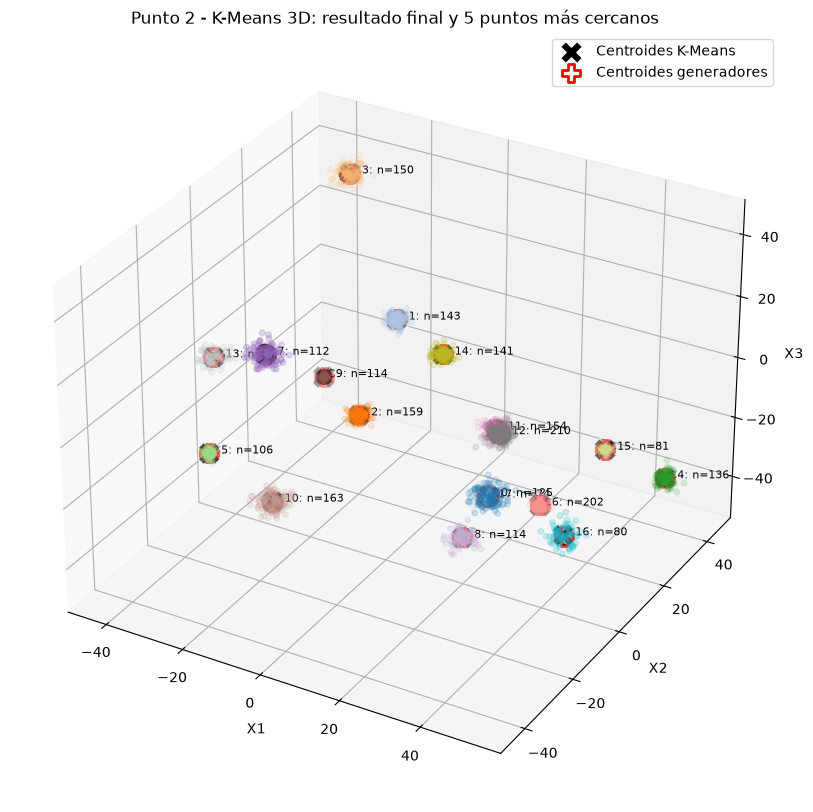

In [16]:
# ============================================================
# GRÁFICA FINAL 3D
# ============================================================

fig = plt.figure(figsize=(13, 10))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    X3[:, 0], X3[:, 1], X3[:, 2],
    c=y3_pred, cmap="tab20", s=16, alpha=0.5
)
ax.scatter(
    centroides_3d_finales[:, 0], centroides_3d_finales[:, 1], centroides_3d_finales[:, 2],
    marker="X", s=260, c="black", edgecolors="white", linewidths=1.2,
    label="Centroides K-Means"
)
ax.scatter(
    centros_3d_generados[:, 0], centros_3d_generados[:, 1], centros_3d_generados[:, 2],
    marker="P", s=170, facecolors="none", edgecolors="red", linewidths=2,
    label="Centroides generadores"
)

for i, indices in indices_5_cercanos_3d.items():
    pts = X3[indices]
    ax.scatter(
        pts[:, 0], pts[:, 1], pts[:, 2],
        s=90, facecolors="none", edgecolors="black", linewidths=1.4
    )
    cx, cy, cz = centroides_3d_finales[i]
    ax.text(cx, cy, cz, f" C{i}: n={conteos_3d[i]}", fontsize=8)

ax.set_title("Punto 2 - K-Means 3D: resultado final y 5 puntos más cercanos")
ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_zlabel("X3")
ax.legend(loc="best")
plt.show()


### Visualización del proceso de entrenamiento en 3D

Se mantiene una inicialización común y se muestran varias etapas para observar cómo los centroides se desplazan hasta alcanzar la convergencia.

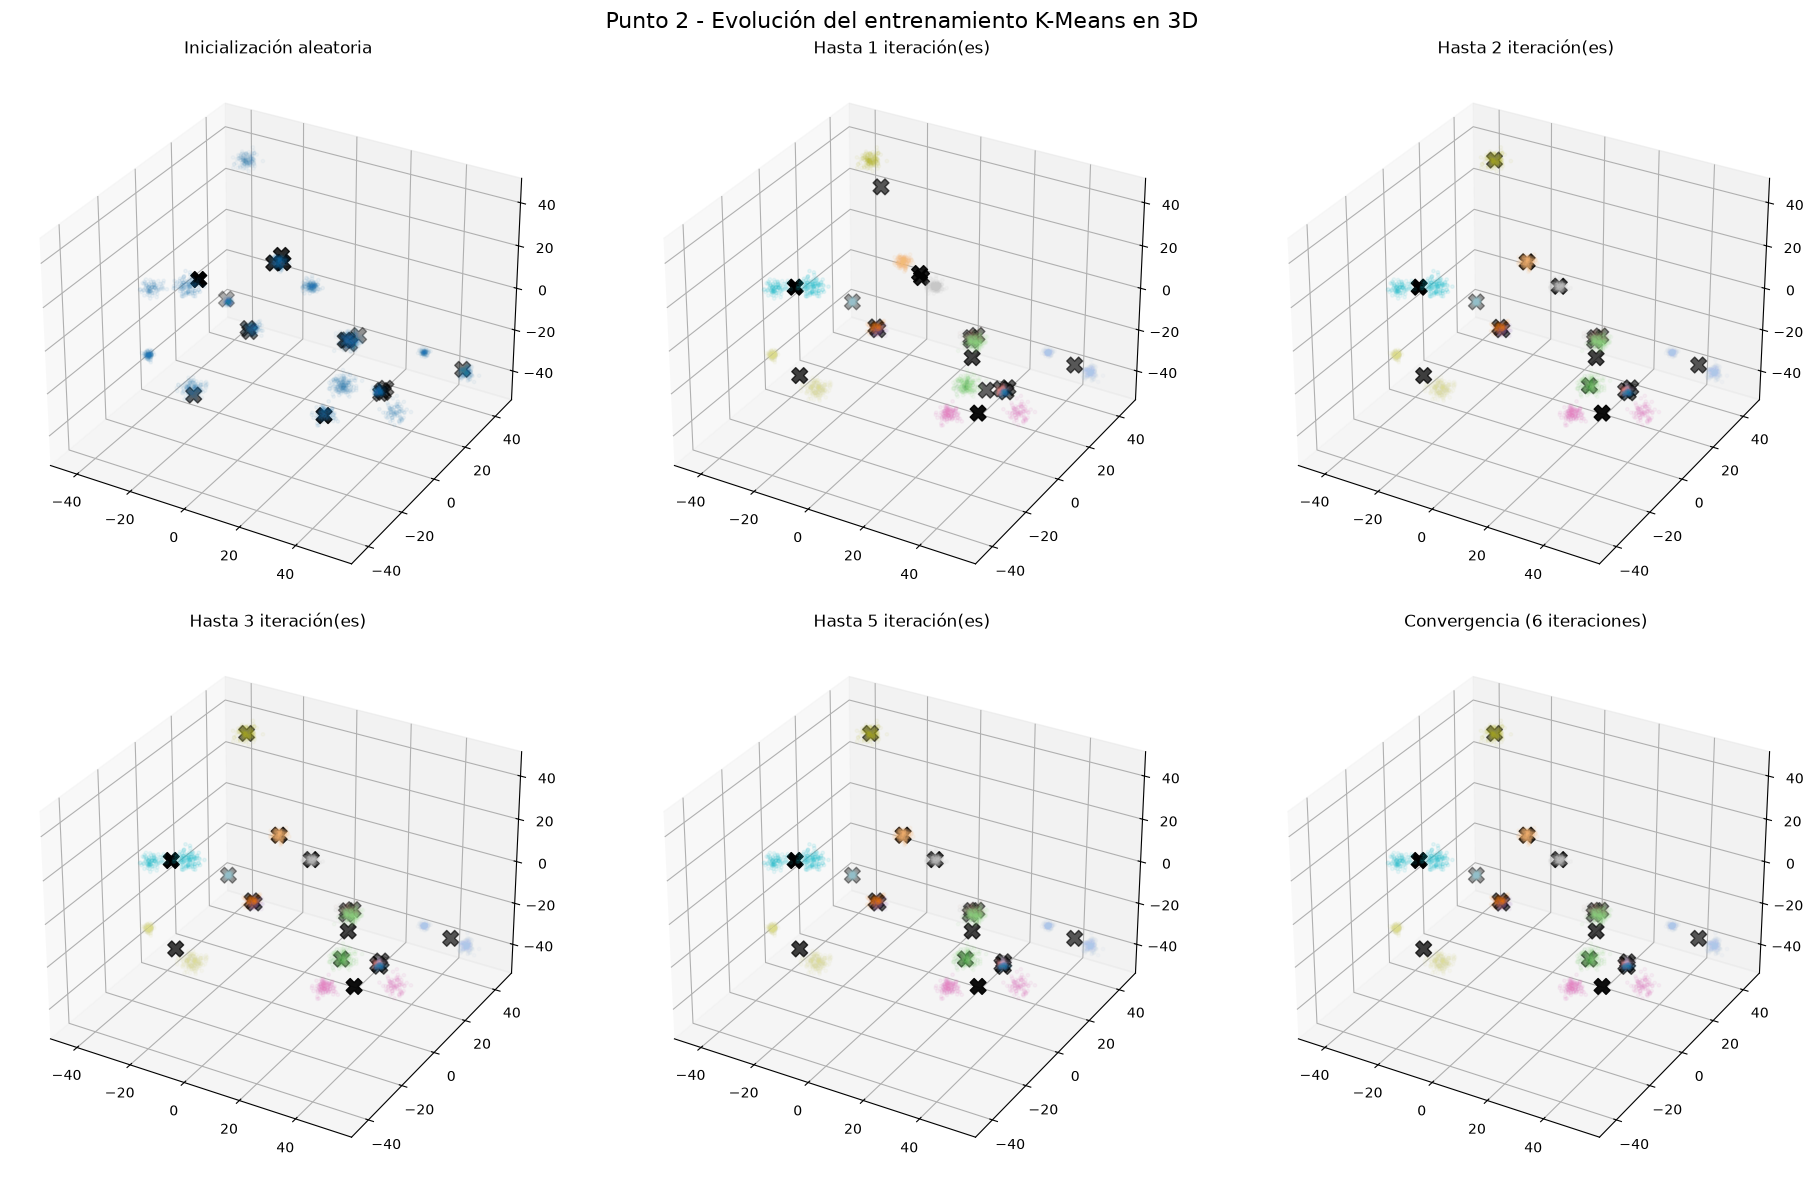

In [17]:
# ============================================================
# PROCESO DE K-MEANS EN 3D
# ============================================================

rng_proceso3 = np.random.default_rng(123)
indices_init3 = rng_proceso3.choice(len(X3), size=k3, replace=False)
centros_init3 = X3[indices_init3].copy()

pasos3 = [1, 2, 3, 5]
modelos3 = []
for max_iter in pasos3:
    m = KMeans(
        n_clusters=k3,
        init=centros_init3,
        n_init=1,
        max_iter=max_iter,
        algorithm="lloyd",
        random_state=123
    ).fit(X3)
    modelos3.append((max_iter, m))

m3_final = KMeans(
    n_clusters=k3,
    init=centros_init3,
    n_init=1,
    max_iter=300,
    algorithm="lloyd",
    random_state=123
).fit(X3)

fig = plt.figure(figsize=(19, 12))

# Inicialización
ax = fig.add_subplot(2, 3, 1, projection="3d")
ax.scatter(X3[:, 0], X3[:, 1], X3[:, 2], s=6, alpha=0.25)
ax.scatter(centros_init3[:, 0], centros_init3[:, 1], centros_init3[:, 2], marker="X", s=130, c="black")
ax.set_title("Inicialización aleatoria")

# Iteraciones parciales
for pos, (max_iter, modelo) in enumerate(modelos3, start=2):
    ax = fig.add_subplot(2, 3, pos, projection="3d")
    ax.scatter(
        X3[:, 0], X3[:, 1], X3[:, 2],
        c=modelo.labels_, cmap="tab20", s=6, alpha=0.30
    )
    ax.scatter(
        modelo.cluster_centers_[:, 0], modelo.cluster_centers_[:, 1], modelo.cluster_centers_[:, 2],
        marker="X", s=130, c="black"
    )
    ax.set_title(f"Hasta {max_iter} iteración(es)")

# Convergencia
ax = fig.add_subplot(2, 3, 6, projection="3d")
ax.scatter(
    X3[:, 0], X3[:, 1], X3[:, 2],
    c=m3_final.labels_, cmap="tab20", s=6, alpha=0.30
)
ax.scatter(
    m3_final.cluster_centers_[:, 0], m3_final.cluster_centers_[:, 1], m3_final.cluster_centers_[:, 2],
    marker="X", s=130, c="black"
)
ax.set_title(f"Convergencia ({m3_final.n_iter_} iteraciones)")

plt.suptitle("Punto 2 - Evolución del entrenamiento K-Means en 3D", fontsize=16)
plt.tight_layout()
plt.show()


En lugar de asignar un grupo a cada muestra (*hard clustering*) se le puede asignar una puntuación (*soft clustering*) en función de su distancia al centroide.

In [18]:
kmeans.transform(X_new)  # la  distancia de cada punto del X_neww

array([[64.61403379, 33.89243811, 48.49796201,  6.11916273, 16.08851257,
        42.14971553, 34.01188873],
       [66.66873906, 36.39352294, 50.13556299,  3.95214587, 15.38972002,
        45.11498274, 35.94867322],
       [61.87563056, 32.10427576, 46.11860736,  8.4628783 , 16.41231129,
        39.37090264, 31.41546908],
       [62.25479746, 31.78907621, 46.55618062,  8.6136275 , 16.84786267,
        39.27724115, 31.82563229]])

Este algoritmo funciona asignando centroides de manera aleatoria y, de manera iterativa, asigna cada instancia a uno de ellos (el más cercano) tras lo cual se recalcula el centroide como el valor promedio de todas las instancias asignadas al grupo.

In [19]:


# kmeans_iter1 = KMeans(n_clusters=5, init="random", n_init=1,
#                      algorithm="full", max_iter=1, random_state=1)
# kmeans_iter1 = KMeans(n_clusters=5, init="random", n_init=1,
#                      algorithm="lloyd", max_iter=1, random_state=1)
# kmeans_iter1 = KMeans(n_clusters=5, init="random", n_init=5,
#                      algorithm="elkan", max_iter=1, random_state=1)
# Configuración del modelo K-Means con inicialización inteligente
kmeans_iter1 = KMeans(n_clusters=k, init="k-means++", n_init=1,
                      algorithm="elkan", max_iter=3, random_state=1)
# kmeans_iter2 = KMeans(n_clusters=5, init="random", n_init=1,
#                      algorithm="full", max_iter=2, random_state=1)
# kmeans_iter2 = KMeans(n_clusters=5, init="random", n_init=5,
#                      algorithm="elkan", max_iter=2, random_state=1)
kmeans_iter2 = KMeans(n_clusters=k, init="k-means++", n_init=1,
                     algorithm="elkan", max_iter=2, random_state=1)

# kmeans_iter3 = KMeans(n_clusters=5, init="random", n_init=1,
#                      algorithm="full", max_iter=3, random_state=1)
# kmeans_iter3 = KMeans(n_clusters=5, init="random", n_init=5,
#                      algorithm="elkan", max_iter=3, random_state=1)
kmeans_iter3 = KMeans(n_clusters=k, init="k-means++", n_init=1,
                     algorithm="elkan", max_iter=3, random_state=1)
kmeans_iter1.fit(X)
kmeans_iter2.fit(X)
kmeans_iter3.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",7
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",1
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",1
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'elkan'
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](7, 2)","[[-43.46,

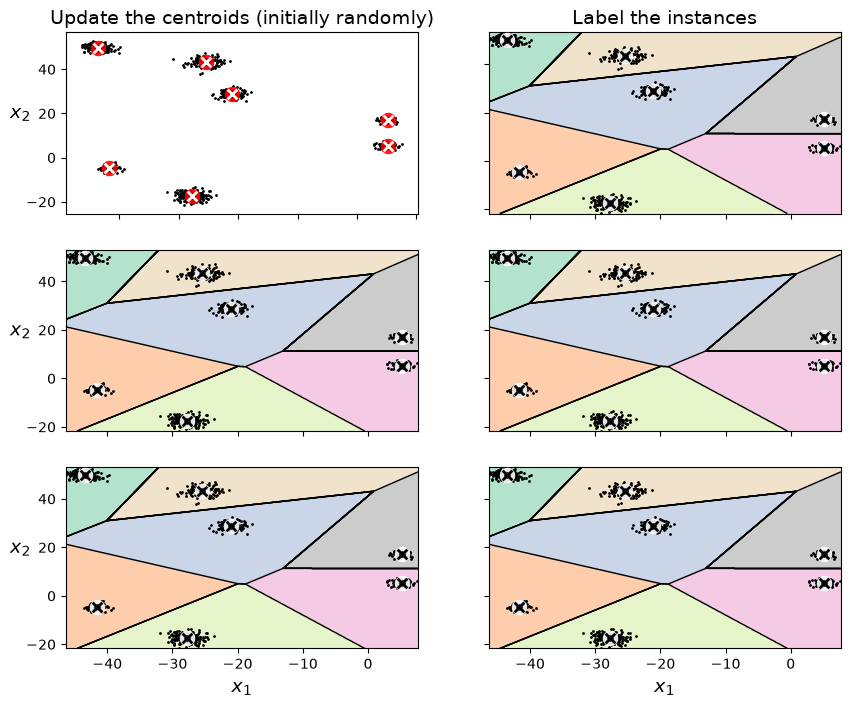

In [20]:
plt.figure(figsize=(10, 8))

plt.subplot(321)
plot_data(X)
plot_centroids(kmeans_iter1.cluster_centers_, circle_color='r', cross_color='w')
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.tick_params(labelbottom=False)
plt.title("Update the centroids (initially randomly)", fontsize=14)

plt.subplot(322)
plot_decision_boundaries(kmeans_iter1, X, show_xlabels=False, show_ylabels=False)
plt.title("Label the instances", fontsize=14)

plt.subplot(323)
plot_decision_boundaries(kmeans_iter1, X, show_centroids=False, show_xlabels=False)
plot_centroids(kmeans_iter2.cluster_centers_)

plt.subplot(324)
plot_decision_boundaries(kmeans_iter2, X, show_xlabels=False, show_ylabels=False)

plt.subplot(325)
plot_decision_boundaries(kmeans_iter2, X, show_centroids=False)
plot_centroids(kmeans_iter3.cluster_centers_)

plt.subplot(326)
plot_decision_boundaries(kmeans_iter3, X, show_ylabels=False)

plt.show()

Esto implica que en función del estado inicial, el algoritmo puede llegar a una solución u otra.

In [21]:
def plot_clusterer_comparison(clusterer1, clusterer2, X, title1=None, title2=None):
    clusterer1.fit(X)
    clusterer2.fit(X)

    plt.figure(figsize=(10, 3.2))

    plt.subplot(121)
    plot_decision_boundaries(clusterer1, X)
    if title1:
        plt.title(title1, fontsize=14)

    plt.subplot(122)
    plot_decision_boundaries(clusterer2, X, show_ylabels=False)
    if title2:
        plt.title(title2, fontsize=14)

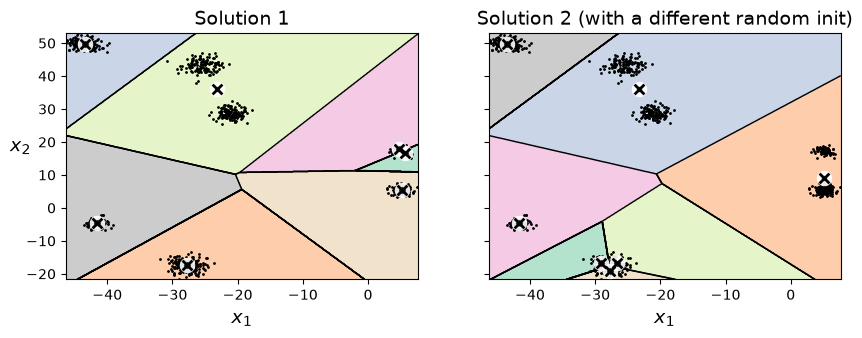

In [22]:
kmeans_rnd_init1 = KMeans(n_clusters=k, init="random", n_init=1,
                         algorithm="elkan", random_state=11)
kmeans_rnd_init2 = KMeans(n_clusters=k, init="random", n_init=1,
                         algorithm="elkan", random_state=19)

plot_clusterer_comparison(kmeans_rnd_init1, kmeans_rnd_init2, X,"Solution 1", "Solution 2 (with a different random init)")

plt.show()

Para minimizar el impacto de la inicialización tenemos varias alternativas: probar varias y quedarnos con la mejor, o usar la inicialización inteligente que ofrece *Scikit-Learn* por defecto.

In [23]:
kmeans_rnd_10_inits = KMeans(n_clusters=k, init="random", n_init=10,
                              algorithm="elkan", random_state=11)        # inicializando 10 y quedandome con el mejor resultado
kmeans_rnd_10_inits.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",7
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",11
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'elkan'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](7, 2)","[[-41.63

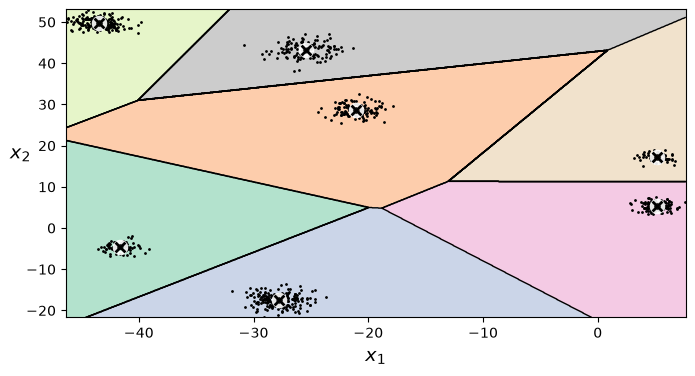

In [24]:
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans_rnd_10_inits, X)
plt.show()

Otras mejoras al algoritmo de *K-Means* incluyen: *K-Means* acelerados (usado por *Scikit-Learn* por defecto y que evita algunos cálculos de distancias) y *mini-batch K-Means* (que puedes usarse si el dataset es tan grande que no cabe en memoria). Vamos a ver un ejemplo de este último caso con el dataset MNIST, para lo cual usaremos el objeto [MiniBatchKMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MiniBatchKMeans.html?highlight=minibatchkmeans#sklearn.cluster.MiniBatchKMeans).

In [25]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1)
mnist.target = mnist.target.astype(np.int64)

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    mnist["data"], mnist["target"], random_state=42)

In [27]:
def load_next_batch(batch_size):
    return X[np.random.choice(len(X), batch_size, replace=False)]

In [28]:
from sklearn.cluster import MiniBatchKMeans

k = 5
n_init = 10
n_iterations = 100
batch_size = 100
init_size = 500
evaluate_on_last_n_iters = 10

best_kmeans = None # aqui creamosS variable para guardar el mejor modelo entrenado
# el entrenamiento de Mini-bacht kmeans
for init in range(n_init):
    minibatch_kmeans = MiniBatchKMeans(n_clusters=k, init_size=init_size)
    X_init = load_next_batch(init_size)
    minibatch_kmeans.partial_fit(X_init)

    minibatch_kmeans.sum_inertia_ = 0
    for iteration in range(n_iterations):
        X_batch = load_next_batch(batch_size)
        minibatch_kmeans.partial_fit(X_batch)
        if iteration >= n_iterations - evaluate_on_last_n_iters:
            minibatch_kmeans.sum_inertia_ += minibatch_kmeans.inertia_

    if (best_kmeans is None or
        minibatch_kmeans.sum_inertia_ < best_kmeans.sum_inertia_):
        best_kmeans = minibatch_kmeans

In [29]:
best_kmeans.score(X)

-24842.29126887959

El algoritmo de *mini-batch K-Means* es más rápido que *K-Means* normal, pero su precisión suele ser peor.

### Encontrando el número óptimo de grupos

Como hemos visto anteriormente, el número de grupos o *clusters* es un hyperparámetro del modelo que debemos definir, y como podrás imaginar si nuestros datos no están etiquetados no será imposible saber qué valor usar. Para ello la solución se basa en usar diferentes valores y utilizar alguna métrica significativa. Una de estas métricas se conoce como el *silhouette score*, que se basa en calcular el coeficiente de silueta (*silhouette coefficient*) de todas las muestras del dataset como $(b-a)/\mathrm{max}(a,b)$ donde $a$ es la distancia mínima al resto de muestras del mismo grupo y $b$ es la distancia media de los grupos más cercanos. Su valor se encuentra entre $1$ y $-1$. Un valor cercano a $1$ indica que la muestra está bien metida en su grupo y lejos de los demás mientras que un valor cercano a $0$ indica que la muestra se encuentra cerca de una frontera de decisión y un valor cercano a $-1$ indica que la muestra está en el grupo incorrecto.

In [30]:
from sklearn.metrics import silhouette_score
silhouette_score(X, kmeans.labels_)

0.8690710284002241

Calculando la métrica para diferentes números de *clusters* podemos encontrar el valor óptimo.

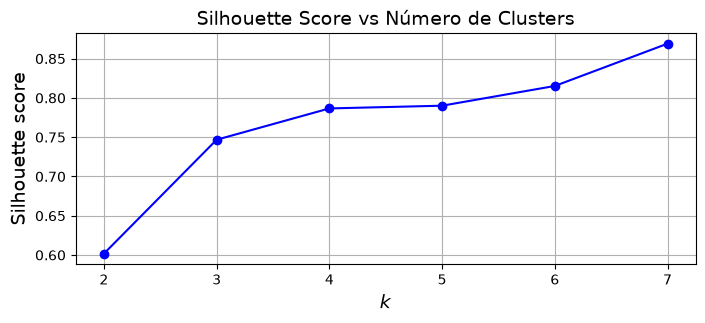

In [31]:
#kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, 10)]
#silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

#max_k = min(20, len(blob_centers))  # no más de los centros generados
#kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, max_k + 1)]
#silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

#plt.figure(figsize=(8, 3))
#plt.plot(range(2, 10), silhouette_scores, "bo-")
#plt.xlabel("$k$", fontsize=14)
#plt.ylabel("Silhouette score", fontsize=14)
#plt.axis([1.8, 8.5, 0.55, 0.7])
#plt.show()

import matplotlib.pyplot as plt

# Definir máximo valor de k
max_k = min(20, len(blob_centers))

# Entrenar un modelo KMeans para cada k de 1 hasta max_k
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, max_k + 1)]

# Calcular silhouette_scores para k ≥ 2
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

# Generar eje x para k de 2 hasta max_k
ks = list(range(2, max_k + 1))

# Graficar
plt.figure(figsize=(8, 3))
plt.plot(ks, silhouette_scores, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.title("Silhouette Score vs Número de Clusters", fontsize=14)
plt.grid(True)
plt.show()


También es muy útil visualizar los diagramas de silueta, en el que visualizaremos todos los coeficientes de silueta ordenados por grupos y su valor.

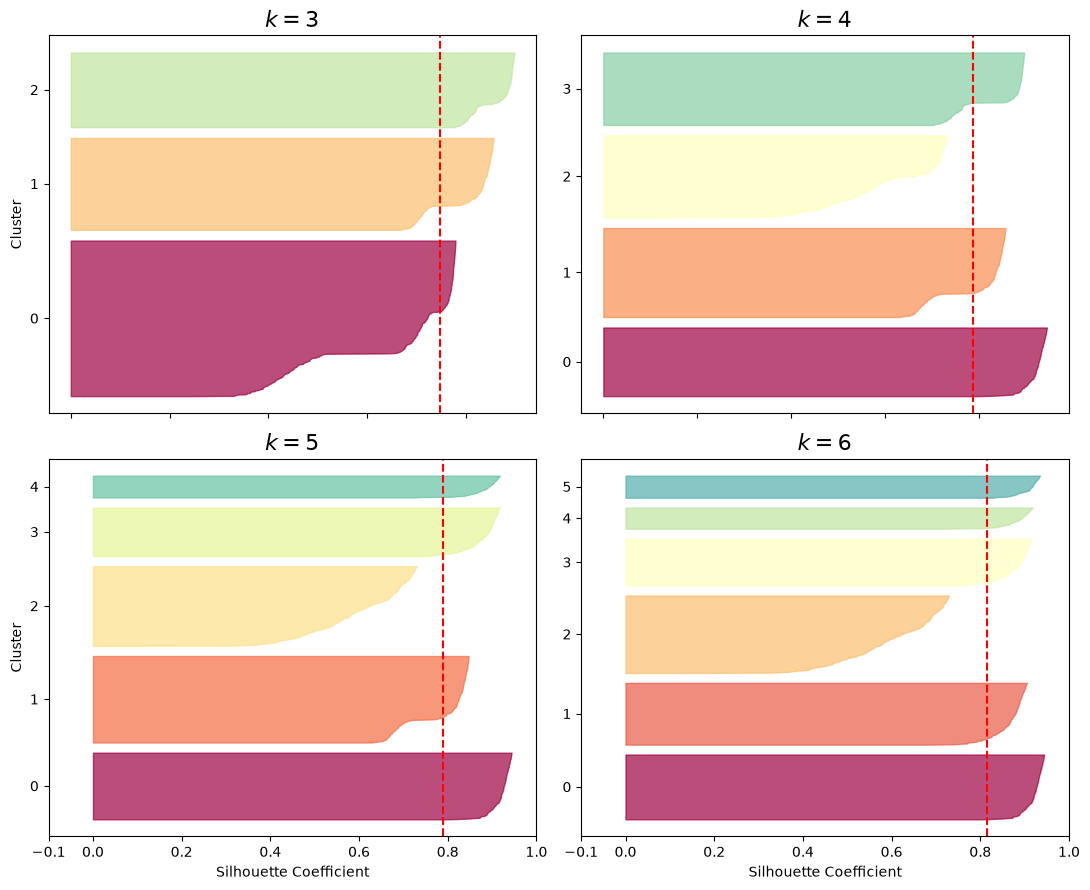

In [32]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter
import matplotlib as mpl

plt.figure(figsize=(11, 9))

valid_ks = [k for k in (3, 4, 5, 6) if k <= len(kmeans_per_k)]  # Filtrar solo los ks válidos


for plot_idx, k in enumerate(valid_ks):
    plt.subplot(2, 2, plot_idx + 1)  # enumerar para evitar errores

    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = mpl.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    if k in (3, 5):
        plt.ylabel("Cluster")

    if k in (5, 6):
        plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        plt.xlabel("Silhouette Coefficient")
    else:
        plt.tick_params(labelbottom=False)

    if k - 2 < len(silhouette_scores):
        plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title(f"$k={k}$", fontsize=16)

plt.tight_layout()
plt.show()


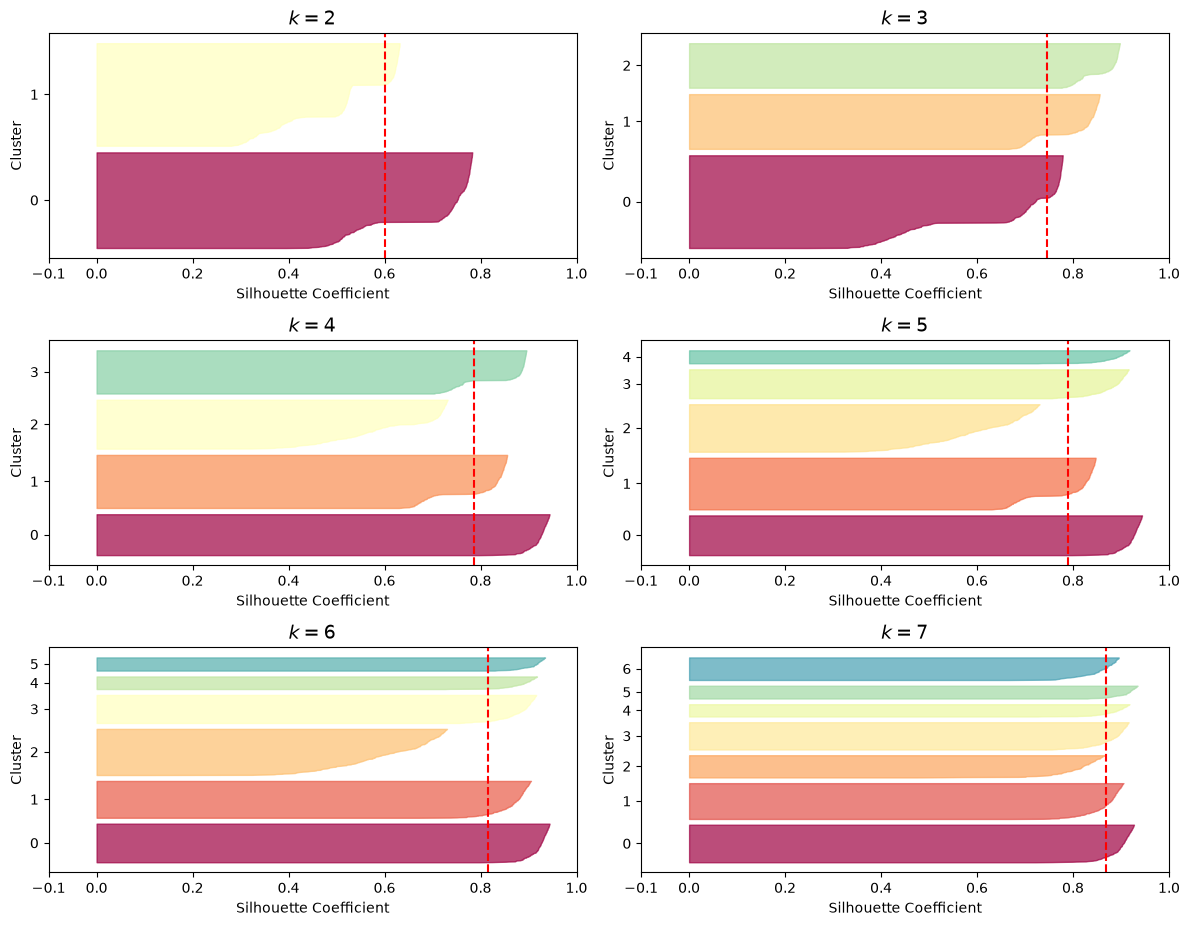

In [33]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter
import matplotlib as mpl

n_ks = len(kmeans_per_k)  # Total de modelos entrenados
plt.figure(figsize=(12, 3 * ((n_ks - 1) // 2 + 1)))  # ajustar el alto automáticamente

for plot_idx, k in enumerate(range(2, n_ks + 1)):  # desde k=2 hasta máximo
    plt.subplot((n_ks - 1) // 2 + 1, 2, plot_idx + 1)

    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = mpl.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    plt.ylabel("Cluster")

    plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
    plt.xlabel("Silhouette Coefficient")

    if k - 2 < len(silhouette_scores):
        plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title(f"$k={k}$", fontsize=14)

plt.tight_layout()
plt.show()


### K-Means para aprendizaje semi-supervisado.

El aprendizaje semi-supervisado (o *Semi-supervised Learning*) comprende el conjunto de técnicas que nos permiten entrenar modelos con datasets parcialmente etiquetados. En esta sección vamos a ver un ejemplo de como podemos aplicar esta técnica con el dataset MNIST y usando *K-Means*. Empezamos descargando el dataset.

In [34]:
from sklearn.datasets import fetch_lfw_people


# Cargar el dataset con imágenes de al menos 70 rostros por persona (puedes ajustar min_faces_per_person)
lfw_dataset = fetch_lfw_people(min_faces_per_person=70, resize=0.4)

# Acceder a los datos
X = lfw_dataset.data          # Imágenes en formato vectorizado (flattened)
y = lfw_dataset.target        # Etiquetas (persona)
target_names = lfw_dataset.target_names  # Nombres de las personas

# Verificar las dimensiones
print("Shape de X:", X.shape)
print("Número de clases:", len(target_names))


Shape de X: (1288, 1850)
Número de clases: 7


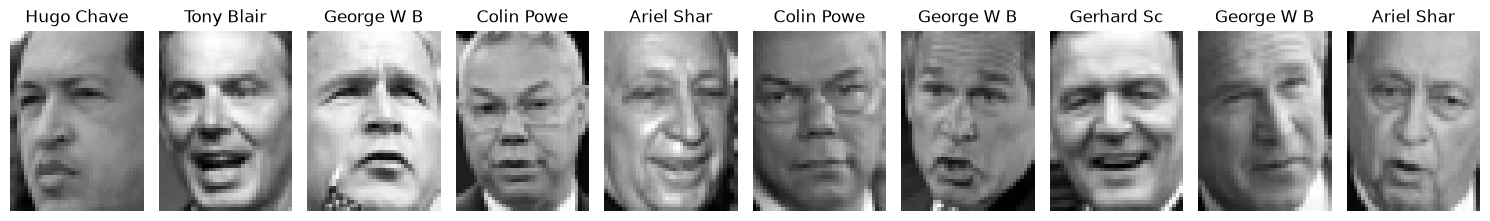

In [35]:
import matplotlib.pyplot as plt

# Mostrar las primeras 10 imágenes del dataset
fig, axes = plt.subplots(1, 10, figsize=(15, 8))
for i in range(10):
    axes[i].imshow(lfw_dataset.images[i], cmap="gray")
    axes[i].axis("off")
    axes[i].set_title(target_names[y[i]][:10])  # mostrar el nombre
plt.tight_layout()
plt.show()


In [36]:
#preparar el dataset
from sklearn.model_selection import train_test_split
import numpy as np

# Cargamos el dataset
lfw = fetch_lfw_people(min_faces_per_person=70, resize=0.4)

X = lfw.data  # características (imagenes aplanadas)
y = lfw.target  # etiquetas (personas)
target_names = lfw.target_names  # nombres de personas

print("Shape de X:", X.shape)  # ejemplo: (1288, 1850)
print("Cantidad de clases:", len(target_names))

# Dividimos en conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)


Shape de X: (1288, 1850)
Cantidad de clases: 7


In [37]:
from sklearn.cluster import KMeans

k = 50  # número de clusters
kmeans = KMeans(n_clusters=k, random_state=42)
X_faces_dist = kmeans.fit_transform(X_train)  # distancia a cada centroide

print("Shape de distancias:", X_faces_dist.shape)


Shape de distancias: (966, 50)


In [38]:
idxs = np.argmin(X_faces_dist, axis=0)  # índice más cercano a cada centroide
X_representative_faces = X_train[idxs]  # imágenes representativas

print("Shape:", X_representative_faces.shape)


Shape: (50, 1850)


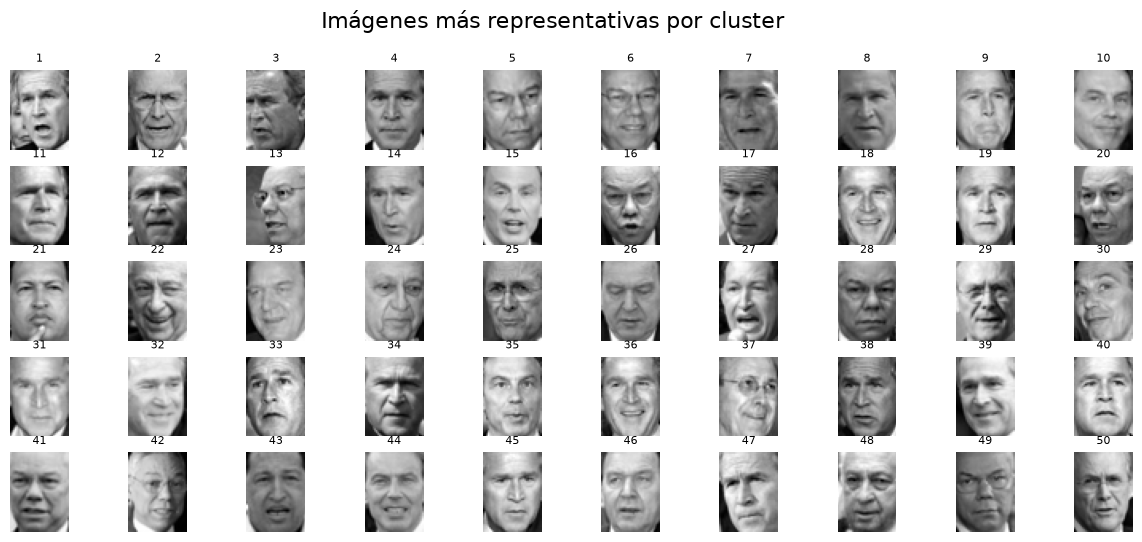

In [39]:
import matplotlib.pyplot as plt

h, w = lfw.images.shape[1:3]  # alto y ancho original

plt.figure(figsize=(15, 6))
for index, face in enumerate(X_representative_faces):
    plt.subplot(5, 10, index + 1)
    plt.imshow(face.reshape(h, w), cmap="gray")
    plt.title(f"{index+1}", fontsize=8)
    plt.axis('off')
plt.suptitle("Imágenes más representativas por cluster", fontsize=16)
plt.show()


In [40]:
# Obtener las etiquetas reales de las imágenes más representativas
y_representative_faces = y_train[idxs]


In [41]:
from sklearn.linear_model import LogisticRegression

log_reg2 = LogisticRegression(multi_class="ovr", solver="lbfgs", max_iter=5000, random_state=42)
%time log_reg2.fit(X_representative_faces, y_representative_faces)

# Evaluamos el modelo en el conjunto de prueba
print("Precisión usando solo imágenes representativas:", log_reg2.score(X_test, y_test))




TypeError: LogisticRegression.__init__() got an unexpected keyword argument 'multi_class'

In [ ]:
log_reg_random = LogisticRegression(multi_class="ovr", solver="lbfgs", max_iter=5000, random_state=42)
%time log_reg_random.fit(X_train[:50], y_train[:50])

# Evaluamos el modelo en el conjunto de prueba
print("Precisión usando 50 imágenes aleatorias:", log_reg_random.score(X_test, y_test))



In [ ]:
# Propagación de etiquetas representativas a todo el conjunto de entrenamiento
y_train_propagated = np.empty(len(X_train))
for i in range(k):
    y_train_propagated[kmeans.labels_ == i] = y_representative_faces[i]

# Entrenamiento con las etiquetas propagadas
log_reg3 = LogisticRegression(multi_class="ovr", solver="lbfgs", max_iter=5000, random_state=42)
%time log_reg3.fit(X_train[:1000], y_train_propagated[:1000])

print("Precisión con 1000 muestras semi-etiquetadas:", log_reg3.score(X_test, y_test))


## Aprendizaje Activo

In [ ]:
# Calculamos las probabilidades de las primeras 1000 muestras
probas = log_reg3.predict_proba(X_train[:1000])

# Obtenemos el índice de la clase más probable para cada muestra
labels_ixs = np.argmax(probas, axis=1)

# Obtenemos la confianza (probabilidad máxima) de cada predicción
confidences = probas[np.arange(len(probas)), labels_ixs]



In [ ]:
# Ordenamos por confianza (de menor a mayor)
sorted_ixs = np.argsort(confidences)

k = 50  # cantidad de muestras "inciertas" a revisar

# Obtenemos las 50 imágenes más inciertas
X_lowest = X_train[:1000][sorted_ixs[:k]]
y_lowest = y_train[:1000][sorted_ixs[:k]]


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
for i in range(10):
    for j in range(5):
        idx = i * 5 + j
        image = X_lowest[idx].reshape(50, 37)
        plt.subplot(10, 5, idx + 1)
        plt.imshow(image, cmap="gray")
        plt.axis("off")
plt.suptitle("50 imágenes más inciertas según el modelo")
plt.tight_layout()
plt.show()


In [ ]:
log_reg_active = LogisticRegression(multi_class="ovr", solver="lbfgs", max_iter=5000, random_state=42)

# Entrenamos con las 50 muestras inciertas (suponemos que ya están etiquetadas correctamente)
%time log_reg_active.fit(X_lowest, y_lowest)

# Evaluamos en el conjunto de prueba
print("Precisión usando aprendizaje activo (50 imágenes inciertas):", log_reg_active.score(X_test, y_test))
